In [1]:
import os
import httpx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

HORIZON = 30          # forward-return window in calendar days
BASE_BUY = 100        # normal daily buy in USD for the DCA backtest
FEE_RATE = 0.001      # assumed transaction fee (0.1%); adjust for your exchange
DEMO = os.environ.get("BTC_FNG_DEMO") == "1"   # synthetic data, for offline testing

ZONES = [  # (name, upper bound, buy multiplier)
    ("Extreme fear", 24, 1.5),
    ("Fear", 44, 1.25),
    ("Neutral", 55, 1.0),
    ("Greed", 75, 0.75),
    ("Extreme greed", 100, 0.5),
]
ZONE_NAMES = [z[0] for z in ZONES]


def zone_of(v):
    for name, upper, mult in ZONES:
        if v <= upper:
            return name, mult
    return ZONES[-1][0], ZONES[-1][2]

In [2]:
def load_fng():
    rows = httpx.get(
        "https://api.alternative.me/fng/", params={"limit": 0, "format": "json"}, timeout=30
    ).json()["data"]
    s = pd.Series(
        {pd.to_datetime(int(r["timestamp"]), unit="s").normalize(): float(r["value"]) for r in rows},
        name="fng",
    )
    return s.sort_index()


def load_price():
    import yfinance as yf
    px = yf.download("BTC-USD", start="2018-02-01", progress=False, auto_adjust=True)["Close"].squeeze()
    px.index = pd.to_datetime(px.index).tz_localize(None).normalize()
    return px.rename("price")


def synthetic():
    rng = np.random.default_rng(0)
    idx = pd.date_range("2019-01-01", periods=1500)
    price = pd.Series(10000 * np.exp(np.cumsum(rng.normal(0.0008, 0.03, len(idx)))), idx, name="price")
    fng = (50 + 350 * price.pct_change(14).rolling(5).mean().fillna(0) + rng.normal(0, 8, len(idx))).clip(0, 100)
    return price, fng.rename("fng")


price, fng = synthetic() if DEMO else (load_price(), load_fng())

df = pd.concat([price, fng], axis=1, join="outer").sort_index().asfreq("D")
df["ret"] = df["price"].pct_change(fill_method=None)
df["fwd"] = df["price"].shift(-HORIZON) / df["price"] - 1
df["zone"] = pd.Categorical(df["fng"].map(lambda v: zone_of(v)[0]), categories=ZONE_NAMES, ordered=True)

valid_days = df.dropna(subset=["price", "fng"])
print(f"{len(valid_days)} matched observations, {df.index.min().date()} to {df.index.max().date()}")
print(df[["price", "fng", "ret", "fwd"]].describe().round(3))

/usr/local/python/3.14.2/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/usr/local/python/3.14.2/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/usr/local/python/3.14.2/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/usr/local/python/3.14.2/lib/python3.14/site-p

3187 matched observations, 2018-02-01 to 2026-10-27
            price       fng       ret       fwd
count    3191.000  3187.000  3190.000  3161.000
mean    40956.641    45.788     0.001     0.039
std     32636.909    22.020     0.033     0.197
min      3236.762     5.000    -0.372    -0.513
25%      9908.504    26.000    -0.013    -0.081
50%     31155.479    44.000     0.001     0.015
75%     64257.285    65.000     0.015     0.139
max    124752.531    95.000     0.187     1.204


In [ ]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(df.index, df["price"], lw=1)
a1.set_yscale("log")
a1.set_ylabel("BTC price (USD, log)")
a2.plot(df.index, df["fng"], lw=0.8, color="tab:orange")
for edge in (25, 75):
    a2.axhline(edge, color="grey", ls=":", lw=0.8)
a2.set_ylabel("Fear & Greed")
plt.tight_layout()
plt.show()

Pearson  (index vs 30-day forward return): 0.13
Spearman (index vs 30-day forward return): 0.068


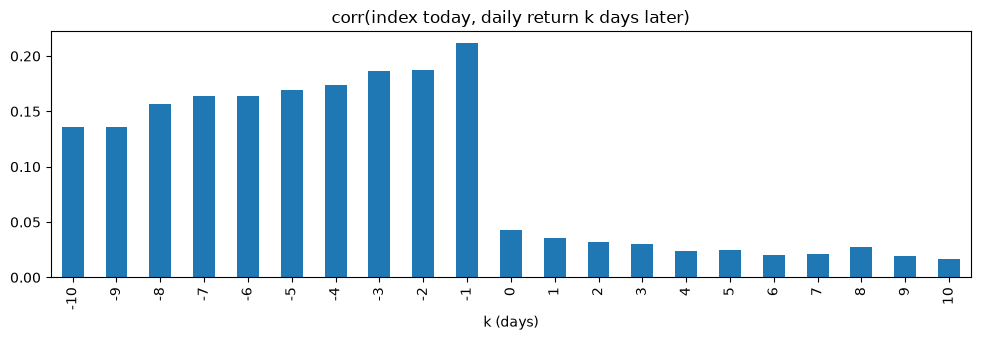

In [3]:
print("Pearson  (index vs 30-day forward return):", round(df["fng"].corr(df["fwd"]), 3))
print("Spearman (index vs 30-day forward return):", round(df["fng"].corr(df["fwd"], method="spearman"), 3))

lags = range(-10, 11)
cc = pd.Series({k: df["fng"].corr(df["ret"].shift(-k)) for k in lags})
cc.plot.bar(figsize=(10, 3.5), title="corr(index today, daily return k days later)")
plt.xlabel("k (days)")
plt.tight_layout()
plt.show()


Forward 7-day return by zone
               days   mean  median  win_rate
zone                                        
Extreme fear    679  0.009   0.009     0.561
Fear            915 -0.001  -0.003     0.470
Neutral         500  0.006   0.001     0.504
Greed           804  0.011   0.005     0.539
Extreme greed   286  0.038   0.017     0.591

Forward 30-day return by zone
               days   mean  median  win_rate
zone                                        
Extreme fear    679  0.032   0.018     0.585
Fear            915  0.005  -0.007     0.477
Neutral         496  0.043   0.042     0.554
Greed           785  0.049   0.017     0.541
Extreme greed   286  0.131   0.057     0.605

Forward 90-day return by zone
               days   mean  median  win_rate
zone                                        
Extreme fear    679  0.026  -0.037     0.459
Fear            895  0.093   0.022     0.514
Neutral         493  0.195   0.074     0.604
Greed           749  0.164   0.048     0.582
Extreme 

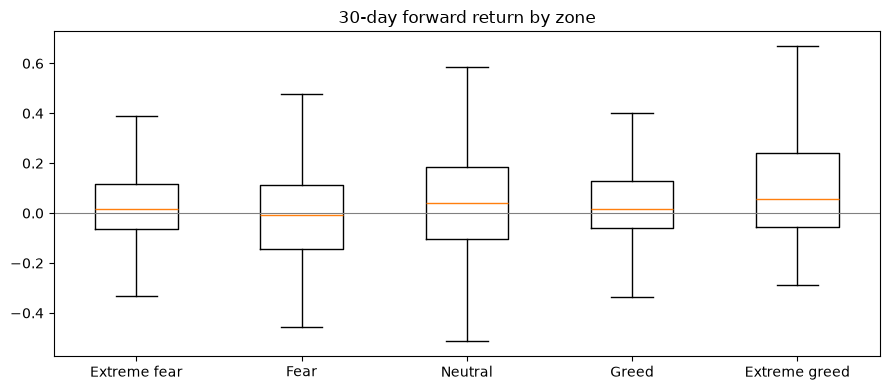

In [4]:
def zone_table(h):
    fwd = df["price"].shift(-h) / df["price"] - 1
    g = fwd.groupby(df["zone"], observed=False)
    return pd.DataFrame({
        "days": g.count(),
        "mean": g.mean(),
        "median": g.median(),
        "win_rate": g.apply(lambda s: (s.dropna() > 0).mean()),
    })


for h in (7, 30, 90):
    print(f"\nForward {h}-day return by zone")
    print(zone_table(h).round(3))

plt.figure(figsize=(9, 4))
plt.boxplot([df.loc[df["zone"] == z, "fwd"].dropna() for z in ZONE_NAMES], showfliers=False)
plt.xticks(range(1, len(ZONE_NAMES) + 1), ZONE_NAMES)
plt.axhline(0, color="grey", lw=0.8)
plt.title(f"{HORIZON}-day forward return by zone")
plt.tight_layout()
plt.show()

In [5]:
s = df.iloc[::HORIZON].dropna(subset=["fng", "fwd", "zone"])
groups = [s.loc[s["zone"] == z, "fwd"] for z in ZONE_NAMES if (s["zone"] == z).sum() >= 2]
print(f"Non-overlapping samples: {len(s)}")

if len(groups) >= 2:
    h_stat, p_kw = stats.kruskal(*groups)
    print(f"Kruskal-Wallis across zones: H={h_stat:.2f}, p={p_kw:.3f}")
else:
    print("Kruskal-Wallis skipped: fewer than two zones have at least two samples.")

if len(s) >= 3 and s["fng"].nunique() > 1 and s["fwd"].nunique() > 1:
    rho, p_rho = stats.spearmanr(s["fng"], s["fwd"])
    print(f"Spearman index vs forward return: rho={rho:.3f}, p={p_rho:.3f}")
else:
    print("Spearman correlation skipped: insufficient variation or fewer than three samples.")

Non-overlapping samples: 106
Kruskal-Wallis across zones: H=2.38, p=0.667
Spearman index vs forward return: rho=0.070, p=0.477


Assumed transaction fee: 0.10% per purchase
                                invested     fees      btc    avg_cost  \
Fixed DCA                       318700.0  318.700  19.4228  16408.5446   
Sentiment DCA (unequal budget)  341275.0  341.275  22.4519  15200.3013   
Sentiment DCA (equal budget)    318700.0  318.700  20.9667  15200.3013   
Buy and hold                    318700.0  318.700  34.7178   9179.7198   

                                 final_value     roi  
Fixed DCA                       1.546042e+06  3.8511  
Sentiment DCA (unequal budget)  1.787153e+06  4.2367  
Sentiment DCA (equal budget)    1.668934e+06  4.2367  
Buy and hold                    2.763516e+06  7.6712  


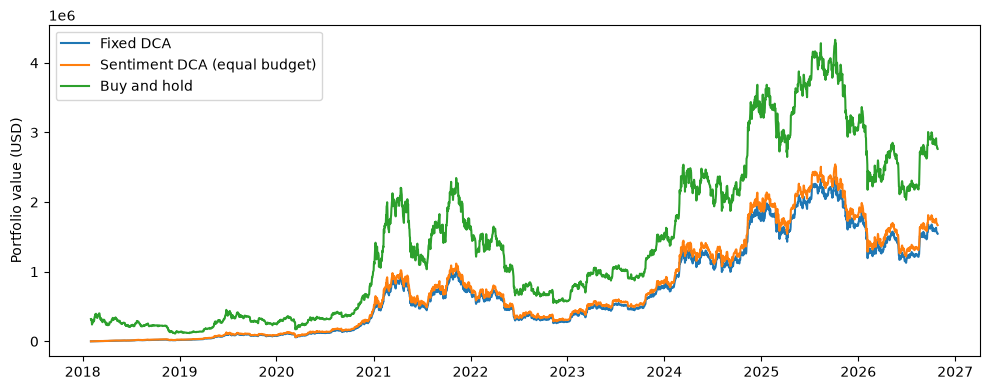

Bad pipe message: %s [b'0.9,image/jxl,image/avif,image/webp,image/apng,*/*;q=0.8\r\nHost: localhost:41807\r\nUser-Agent: Mozilla/5.0 (Window', b'NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/156.0.0.0 Safari/537.36\r\nAccept-Encoding: gzip,']
Bad pipe message: %s [b'eflate, br, zstd\r\nAccept-Langua']
Bad pipe message: %s [b': en-US,en;q=0.9\r\nCache-Control: max-age=0\r\nReferer: https://github.com/\r\nX-Request-ID: 0686f1651cdd7b', b'9657a5345659b53e\r\nX-Real-IP: 14.139.240.50\r\nX-For']


In [ ]:
d = df.dropna(subset=["price", "fng"]).copy()
d["mult"] = d["fng"].map(lambda v: zone_of(v)[1])
last = d["price"].iloc[-1]


def evaluate(spend):
    fees = spend.sum() * FEE_RATE
    coins = (spend * (1 - FEE_RATE) / d["price"]).sum()
    invested = spend.sum()
    return {"invested": invested, "fees": fees, "btc": coins, "avg_cost": invested / coins,
            "final_value": coins * last, "roi": coins * last / invested - 1}


fixed = pd.Series(BASE_BUY, index=d.index, dtype=float)
sent = BASE_BUY * d["mult"]
sent_eq = sent * fixed.sum() / sent.sum()   # same total budget as fixed DCA
buy_hold = pd.Series(0.0, index=d.index)
buy_hold.iloc[0] = fixed.sum()

res = pd.DataFrame({
    "Fixed DCA": evaluate(fixed),
    "Sentiment DCA (unequal budget)": evaluate(sent),
    "Sentiment DCA (equal budget)": evaluate(sent_eq),
    "Buy and hold": evaluate(buy_hold),
}).T
print(f"Assumed transaction fee: {FEE_RATE:.2%} per purchase")
print(res.round(4))

plt.figure(figsize=(10, 4))
for label, spend in (("Fixed DCA", fixed), ("Sentiment DCA (equal budget)", sent_eq), ("Buy and hold", buy_hold)):
    coins_bought = (spend * (1 - FEE_RATE) / d["price"]).cumsum()
    plt.plot(d.index, coins_bought * d["price"], label=label)
plt.legend()
plt.ylabel("Portfolio value (USD)")
plt.tight_layout()
plt.show()